# TASK 1 - Clustering

In [1]:
!python --version

Python 3.10.14


In [2]:
pip install -r /kaggle/input/requirements1/requirements.txt

  Using cached pandas-1.5.3-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (11 kB)
Using cached pandas-1.5.3-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (12.1 MB)
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf 24.8.3 requires cubinlinker, which is not installed.
cudf 24.8.3 requires cupy-cuda11x>=12.0.0, which is not installed.
cudf 24.8.3 requires ptxcompiler, which is not installed.
cuml 24.8.0 requires cupy-cuda11x>=12.0.0, which is not installed.
dask-cudf 24.8.3 requires cupy-cuda11x>=12.0.0, which is not installed.
beatrix-jupyterlab 2024.66.154055 requires jupyterlab~=3.6.0, but you have jupyterlab 4.2.5 which is incompatible.
bigframes 0.22.0 requires google-clou

In [3]:
  !conda install dask -y                     # either conda install
  !python -m pip install "dask[dataframe]" --upgrade  # or python -m pip install

Channels:
 - rapidsai
 - nvidia
 - nodefaults
 - conda-forge
 - defaults
 - pytorch
Platform: linux-64
Solving environment: done

# All requested packages already installed.

  Using cached pandas-2.2.3-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (89 kB)
Using cached pandas-2.2.3-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (13.1 MB)
  Attempting uninstall: pandas
    Found existing installation: pandas 1.5.3
    Uninstalling pandas-1.5.3:
      Successfully uninstalled pandas-1.5.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf 24.8.3 requires cubinlinker, which is not installed.
cudf 24.8.3 requires cupy-cuda11x>=12.0.0, which is not installed.
cudf 24.8.3 requires ptxcompiler, which is not installed.
cuml 24.8.0 requires cupy-cuda11x>=12.0.0, which is not installed.
dask-cudf 24.8.3 requires cupy-cuda11x>=12.0.0, w

In [4]:
# Please turn on GPU
import sys

!cp ../input/rapids/rapids.21.06 /opt/conda/envs/rapids.tar.gz
!cd /opt/conda/envs/ && tar -xzvf rapids.tar.gz > /dev/null
!rm /opt/conda/envs/rapids.tar.gz

sys.path += ["/opt/conda/envs/rapids/lib/python3.7/site-packages"]
sys.path += ["/opt/conda/envs/rapids/lib/python3.7"]
sys.path += ["/opt/conda/envs/rapids/lib"]
!cp /opt/conda/envs/rapids/lib/libxgboost.so /opt/conda/lib/

In [5]:
# LOAD LIBRARIES
import cudf, cuml
import pandas as pd, numpy as np, os
from cuml.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
print('cuML version',cuml.__version__)

cuML version 24.08.00


In [6]:
import pandas
from typing import Tuple, Dict, Any
from cuml.preprocessing import StandardScaler

def __transform_single_features(dataset: pandas.DataFrame, transformation: str) -> Tuple[
    pandas.DataFrame, Dict[str, Any]]:
    match transformation:
        case "standard":
            transformed_dataset = dataset.copy().select_dtypes(exclude=["object", "category", "bool", "datetime64"])
            transformations = dict()

            for feature in transformed_dataset.columns:
                transformations[feature] = StandardScaler()
                transformed_feature = transformations[feature].fit_transform(transformed_dataset[[feature]]).squeeze()
                transformed_dataset = transformed_dataset.astype({feature: transformed_feature.dtype})
                transformed_dataset.loc[:, feature] = transformed_feature
        case _:
            raise ValueError(f"Unknown transformation: {transformation}")

    return transformed_dataset, transformations


def center_and_scale(dataset: pandas.DataFrame) -> Tuple[pandas.DataFrame, Dict[str, Any]]:
    """Shifts data to the origin: removes mean and scales by standard deviation all numeric features. Returns a copy of the dataset."""
    return __transform_single_features(dataset, "standard")

In [7]:
import pandas
import copy
from cuml.metrics.cluster import silhouette_score
from cuml.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.model_selection import ParameterSampler
import pandas
import numpy as np
import seaborn
import pandas as pd
import cupy as cp

# show all elements of a dataframe
# pandas.set_option("display.max_rows", None)
pandas.set_option("display.max_columns", None)

In [8]:
# since several algorithms are randomized, we set a seed to repeat them
RANDOM_STATE = 42
df_merged = pd.read_csv('/kaggle/input/d/mikymatt/cyclist-cleaned/cleaned.csv', skipinitialspace=True)
df = df_merged[['profile', 'climb_total', 'length']].dropna(subset=['profile', 'climb_total', 'length'])
n_clusters = 5
# load dataset
normalized_df, normalization_scalers_df = center_and_scale(df)
normalized_df = normalized_df.dropna(subset=['profile', 'climb_total', 'length']).sample(n=100000, random_state=RANDOM_STATE)

In [9]:
print(normalized_df)

         profile  climb_total    length
312789 -1.050992    -1.579081 -1.878910
272079  0.288156     1.311708  1.610546
241153  1.627304     0.346363  0.563709
97704   1.627304     2.043212  0.563709
128766  0.957730     1.822112  0.995737
...          ...          ...       ...
72393   0.288156     0.996172  1.294834
89096  -1.050992    -0.131063  0.031983
158640 -0.381418    -1.317508 -2.008518
39263  -1.050992    -1.019960 -0.788870
108328 -0.381418     0.086289 -0.208956

[100000 rows x 3 columns]


In [10]:
# computing sample densities for DBScan to avoid arbitrary values
# maximum distance between any two points in the dataset
maximum_distance = abs(normalized_df.max() - normalized_df.min()).sum().item()
average_concentration = normalized_df.shape[0] / maximum_distance


# set model space
base_algorithms = [
    KMeans,
    DBSCAN,
    # AgglomerativeClustering,
]
base_algorithms_names = [
    "kmeans",
    "dbscan",
    # "agglomerative",
]

# what hyperparameters does each model have?
hyperparameters_per_algorithm = [
    {
        "n_clusters": list(range(2, 8)) + [16],
        "max_iter": [10],
        "random_state": [RANDOM_STATE]
    },
    {
        "eps": average_concentration * np.arange(0.0001, 0.0006, 0.0001),
        "max_mbytes_per_batch": [1024],
        "min_samples": [5],
    },
    # {
    #    "n_clusters": list(range(2, 8)) + [16]
    # },
]

results_per_algorithm = list()
fit_models = list()
clusterings = list()
for algorithm, algorithm_name, hyperparameters in zip(base_algorithms, base_algorithms_names, hyperparameters_per_algorithm):
    print("start execution ->", algorithm_name)

    sampled_hyperparameters = list(ParameterSampler(
        copy.deepcopy(hyperparameters),
        n_iter=10,
        random_state=RANDOM_STATE
    ))

    X_gpu = cp.asarray(normalized_df[['climb_total', 'length']])

    models = []
    clusterings_per_algorithm = []
    for selected_hyperparameters in sampled_hyperparameters:
        model = algorithm(**selected_hyperparameters)
        labels = model.fit_predict(X_gpu)
        print("\talgorithm name ->", algorithm_name, "hyperparameters ->", selected_hyperparameters)
        models.append(model)
        clusterings_per_algorithm.append(labels)
    fit_models += models
    clusterings += clusterings_per_algorithm
    for clustering, selected_hyperparameters in zip(clusterings_per_algorithm, sampled_hyperparameters):
        selected_hyperparameters["algorithm"] = algorithm_name
        selected_hyperparameters["n_clusters"] = len(np.unique(clustering))
    results_per_algorithm += sampled_hyperparameters
    
    print("end execution")

results_df = pandas.DataFrame.from_records(results_per_algorithm)
results_df.loc[:, "random_state"] = RANDOM_STATE

results_df.loc[results_df["max_iter"].isna(), "max_iter"] = -1
results_df.loc[results_df["eps"].isna(), "eps"] = -1

results_df = results_df.astype({"n_clusters": int, "random_state": int})
results_df

start execution -> kmeans
	algorithm name -> kmeans hyperparameters -> {'random_state': 42, 'n_clusters': 2, 'max_iter': 10}
	algorithm name -> kmeans hyperparameters -> {'random_state': 42, 'n_clusters': 3, 'max_iter': 10}


/opt/conda/lib/python3.10/site-packages/sklearn/model_selection/_search.py:320: UserWarning: The total space of parameters 7 is smaller than n_iter=10. Running 7 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


	algorithm name -> kmeans hyperparameters -> {'random_state': 42, 'n_clusters': 4, 'max_iter': 10}
	algorithm name -> kmeans hyperparameters -> {'random_state': 42, 'n_clusters': 5, 'max_iter': 10}
	algorithm name -> kmeans hyperparameters -> {'random_state': 42, 'n_clusters': 6, 'max_iter': 10}
	algorithm name -> kmeans hyperparameters -> {'random_state': 42, 'n_clusters': 7, 'max_iter': 10}
	algorithm name -> kmeans hyperparameters -> {'random_state': 42, 'n_clusters': 16, 'max_iter': 10}
end execution
start execution -> dbscan


/opt/conda/lib/python3.10/site-packages/sklearn/model_selection/_search.py:320: UserWarning: The total space of parameters 5 is smaller than n_iter=10. Running 5 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


	algorithm name -> dbscan hyperparameters -> {'min_samples': 5, 'max_mbytes_per_batch': 1024, 'eps': 0.7405489271864204}
	algorithm name -> dbscan hyperparameters -> {'min_samples': 5, 'max_mbytes_per_batch': 1024, 'eps': 1.4810978543728408}
	algorithm name -> dbscan hyperparameters -> {'min_samples': 5, 'max_mbytes_per_batch': 1024, 'eps': 2.221646781559261}
	algorithm name -> dbscan hyperparameters -> {'min_samples': 5, 'max_mbytes_per_batch': 1024, 'eps': 2.9621957087456816}
	algorithm name -> dbscan hyperparameters -> {'min_samples': 5, 'max_mbytes_per_batch': 1024, 'eps': 3.7027446359321017}
end execution


,random_state,n_clusters,max_iter,algorithm,min_samples,max_mbytes_per_batch,eps
0,42,2,10.0,kmeans,NaN,NaN,-1.000000
1,42,3,10.0,kmeans,NaN,NaN,-1.000000
2,42,4,10.0,kmeans,NaN,NaN,-1.000000
3,42,5,10.0,kmeans,NaN,NaN,-1.000000
4,42,6,10.0,kmeans,NaN,NaN,-1.000000
5,42,7,10.0,kmeans,NaN,NaN,-1.000000
6,42,16,10.0,kmeans,NaN,NaN,-1.000000
7,42,2,-1.0,dbscan,5.0,1024.0,0.740549
8,42,1,-1.0,dbscan,5.0,1024.0,1.481098
9,42,1,-1.0,dbscan,5.0,1024.0,2.221647


In [11]:
# Convert normalized_df to a CuPy array (assuming normalized_df is a pandas DataFrame)
normalized_df_gpu = cp.asarray(normalized_df.to_numpy())
# Compute silhouette scores using GPU
silhouette_per_model = [
    silhouette_score(normalized_df_gpu, clustering) 
    if len(cp.unique(clustering)) > 1 else -1
    for clustering in clusterings
]

results_df.loc[:, "silhouette"] = silhouette_per_model
results_df = results_df.sort_values(by="silhouette", ascending=False)

<Axes: xlabel='n_clusters', ylabel='silhouette'>

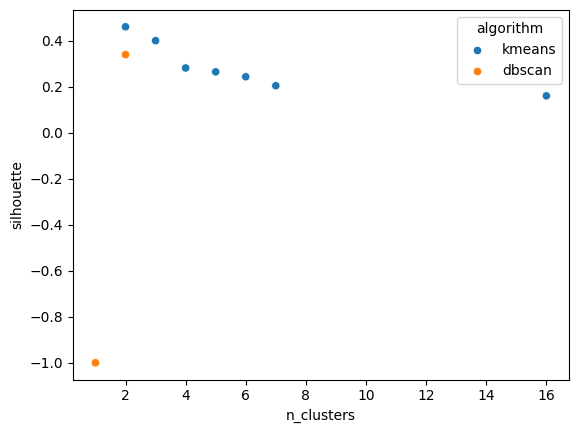

In [12]:
import seaborn

seaborn.scatterplot(
    results_df,
    x="n_clusters",
    y="silhouette",
    hue="algorithm"
)

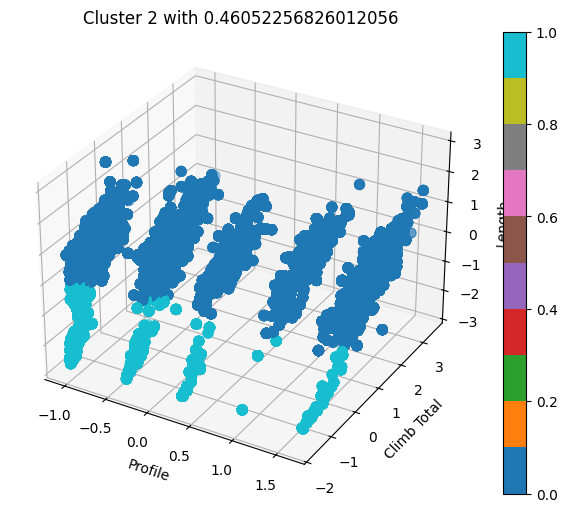

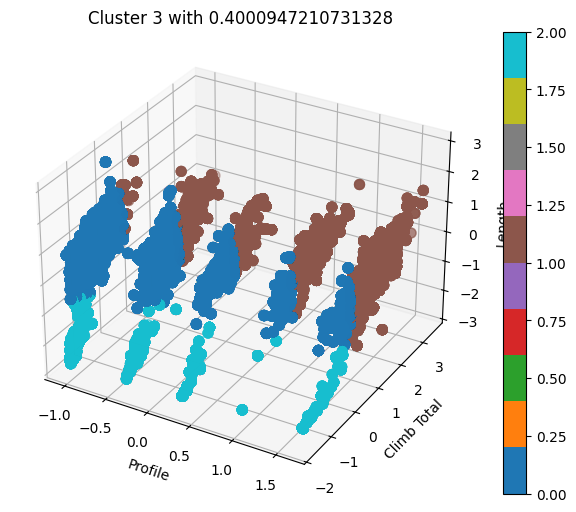

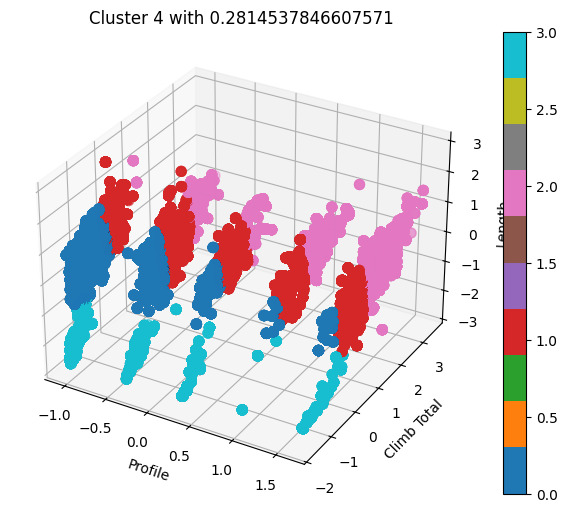

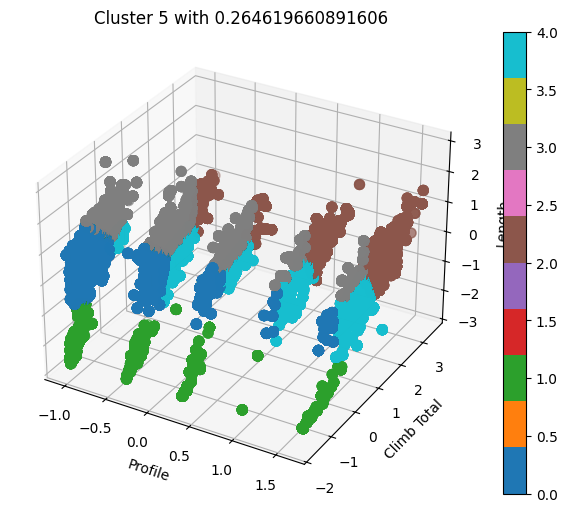

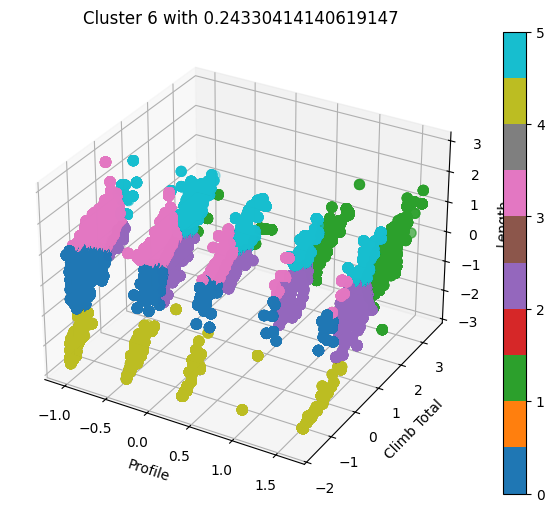

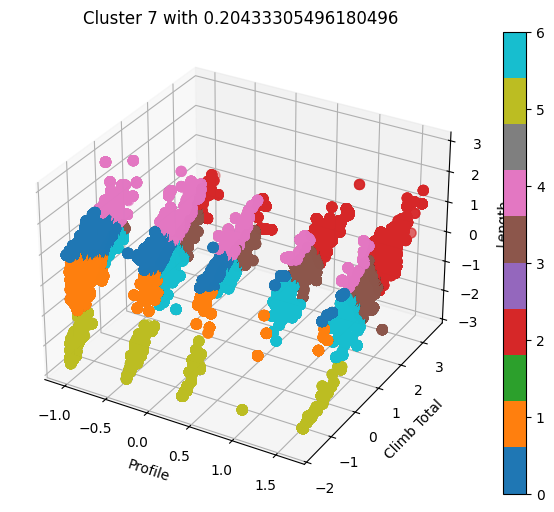

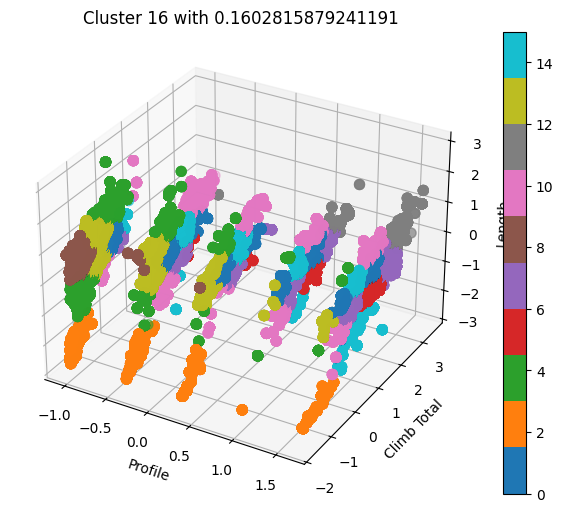

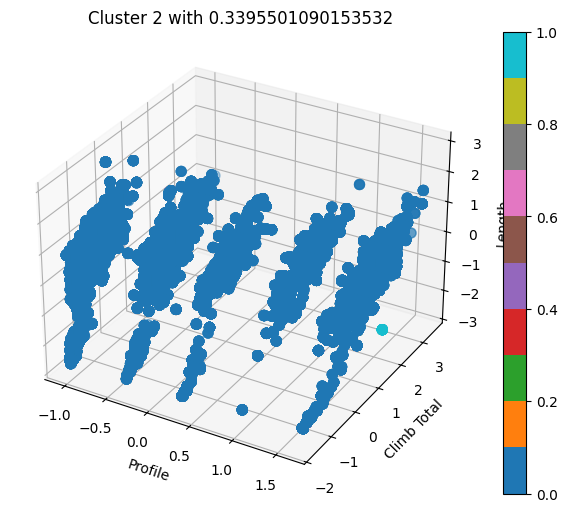

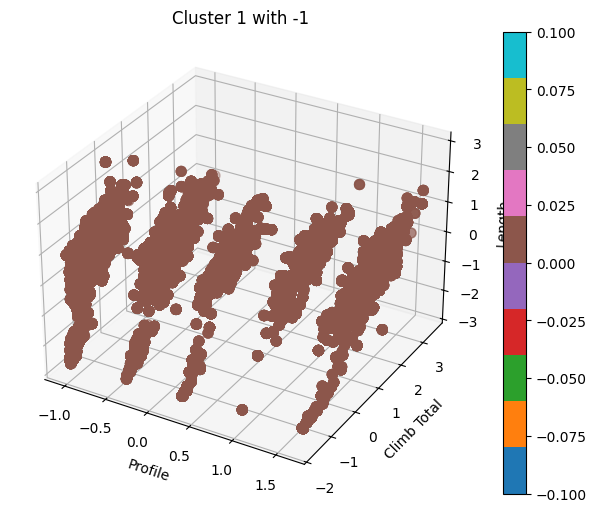

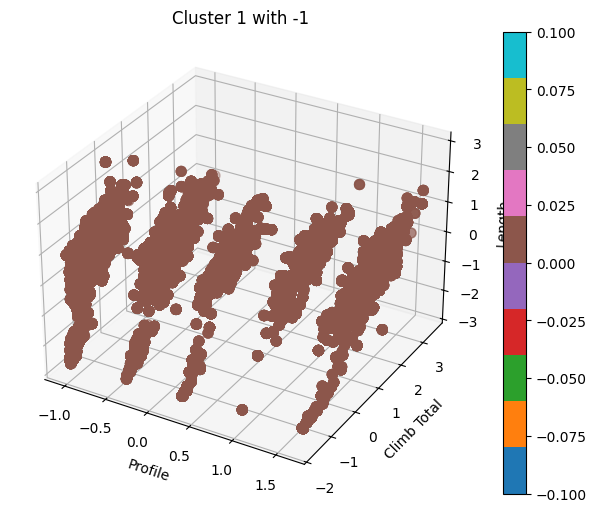

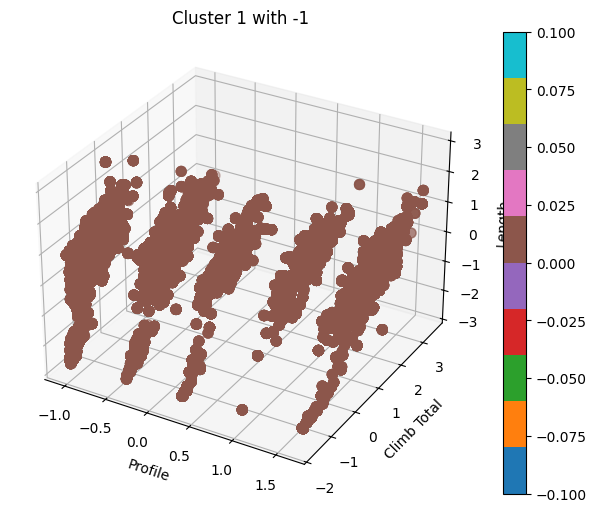

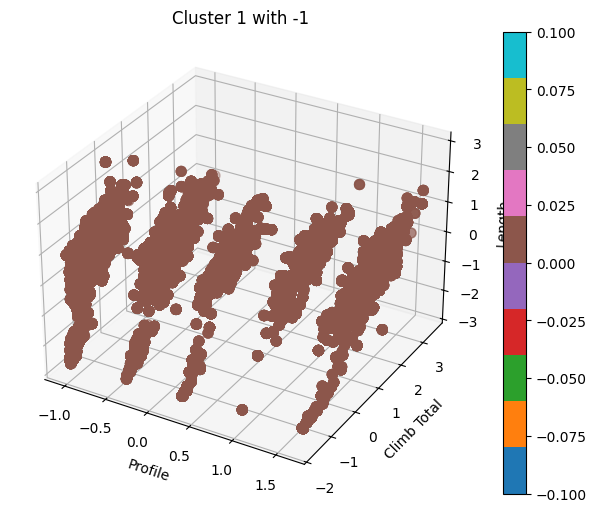

In [13]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
from cuml.metrics.cluster import silhouette_score

for i, clustering in enumerate(clusterings):
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')
    
    scatter = ax.scatter(
        normalized_df["profile"],
        normalized_df["climb_total"],
        normalized_df["length"],
        c=clustering.get(),
        cmap='tab10',
        s=50
    )

    unique_labels = np.unique(clustering)
    ax.set_title(f'Cluster {len(unique_labels)} with {silhouette_per_model[i]}')
    ax.set_xlabel('Profile')
    ax.set_ylabel('Climb Total')
    ax.set_zlabel('Length')
    fig.colorbar(scatter, ax=ax)
    
    plt.show()
